In [32]:
%pip install -U langchain-ollama langchain-neo4j langchain-experimental

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [33]:
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters.character import RecursiveCharacterTextSplitter
import ollama
import re

fetch data

In [34]:
def cleanText(text):
    text = re.sub(r'-\n(\w)', r'\1', text)     # re-join words hyphenated across lines
    text = text.replace('•', '\n- ')           # bullets as their own lines
    text = re.sub(r'[ \t]+', ' ', text)        # collapse spaces/tabs only
    text = re.sub(r'\n{3,}', '\n\n', text)     # cap blank lines
    return text.strip()

In [35]:
loader = PyPDFLoader("data/kejriwal-et-al-2019-knowledge-graphs-construction-management-and-querying.pdf")
pages = loader.load()

In [36]:
for page in pages: 
    page.page_content = cleanText(page.page_content) 

split into chunks

In [37]:
splitter = RecursiveCharacterTextSplitter(chunk_size = 800, chunk_overlap= 100) # created an instance of the text splitter
chunks = splitter.split_documents(pages)

vectorize 

In [38]:
# functions & global variables 

def createEmbedding(text):
    response = ollama.embed(
    model='nomic-embed-text-v2-moe',
    input=text,
    )
    return response.embeddings[0]

In [39]:
doc_embeddings = [] # this is our list of embeddings from out document

for chunk in chunks:
    chunk_embedding = createEmbedding(chunk.page_content)
    doc_embeddings.append(chunk_embedding) 

### Creating a knowledge graph

pass data into llm to disover relationships and nodes,  The entity and relationship types would become labels  and relationship types in the graph

In [40]:
from langchain_ollama import ChatOllama
from langchain_neo4j import Neo4jGraph, LLMGraphTransformer

In [41]:
llm = ChatOllama(model="llama3.2:1b", temperature=0)

In [42]:
graph = Neo4jGraph(url="neo4j://127.0.0.1:7687", username="neo4j", password="neo4j12345678")

In [43]:
graph

In [44]:
transformer = LLMGraphTransformer(llm=llm)

In [45]:
chunks[0].page_content

'Semantic Web 10 (2019) 961–962 961\nDOI 10.3233/SW-190370\nIOS Press\nKnowledge graphs: Construction,\nmanagement and querying\nEditorial\nMayank Kejriwal a,*, Juan Sequeda b and Vanessa Lopezc\na Information Sciences Institute, University of Southern California, Los Angeles, CA, USA\nE-mail: kejriwal@isi.edu\nb data.world, Austin, TX, USA\nE-mail: juan@data.world\nc IBM, Dublin, Ireland\nE-mail: vanlopez@ie.ibm.com\nKeywords: Knowledge graphs, knowledge graph querying, knowledge graph construction, applications, linked data, knowledge\ngraph management\nGraphs have been one of the fundamental data models in Artiﬁcial Intelligence and Databases, but the\nastounding growth of the Web has brought them to'

In [46]:
chunks[0]

Document(metadata={'producer': 'PyPDF', 'creator': 'PyPDF', 'creationdate': '', 'subject': 'Semantic Web 2019.10:961-962', 'title': 'Knowledge graphs: Construction, management and querying', 'source': 'data/kejriwal-et-al-2019-knowledge-graphs-construction-management-and-querying.pdf', 'total_pages': 2, 'page': 0, 'page_label': '961'}, page_content='Semantic Web 10 (2019) 961–962 961\nDOI 10.3233/SW-190370\nIOS Press\nKnowledge graphs: Construction,\nmanagement and querying\nEditorial\nMayank Kejriwal a,*, Juan Sequeda b and Vanessa Lopezc\na Information Sciences Institute, University of Southern California, Los Angeles, CA, USA\nE-mail: kejriwal@isi.edu\nb data.world, Austin, TX, USA\nE-mail: juan@data.world\nc IBM, Dublin, Ireland\nE-mail: vanlopez@ie.ibm.com\nKeywords: Knowledge graphs, knowledge graph querying, knowledge graph construction, applications, linked data, knowledge\ngraph management\nGraphs have been one of the fundamental data models in Artiﬁcial Intelligence and Datab

In [47]:
chunks[1]

Document(metadata={'producer': 'PyPDF', 'creator': 'PyPDF', 'creationdate': '', 'subject': 'Semantic Web 2019.10:961-962', 'title': 'Knowledge graphs: Construction, management and querying', 'source': 'data/kejriwal-et-al-2019-knowledge-graphs-construction-management-and-querying.pdf', 'total_pages': 2, 'page': 0, 'page_label': '961'}, page_content='astounding growth of the Web has brought them to\nthe forefront. Graph models and databases have always served as an interesting frontier of research in the\ndatabase and data mining communities; however, with\nthe advent of knowledge graphs, we are now starting\nto see Web-scale commercial applications that are directly pertinent to research that has long been a staple in the Semantic Web and the widespread use of\nknowledge graphs across diverse data-driven industries, changing the way information is being produced\nand consumed both by users and software programs.\nA knowledge graph, as most practitioners now understand the term, is unde

In [48]:
graph_documents = transformer.convert_to_graph_documents([chunks[0]])

In [49]:
graph_documents_two = transformer.convert_to_graph_documents([chunks[1]])

In [50]:
graph_documents_three = transformer.convert_to_graph_documents([chunks[2]])

In [51]:
graph_documents_four = transformer.convert_to_graph_documents([chunks[3]])

In [52]:
graph_documents_five = transformer.convert_to_graph_documents([chunks[4]])

In [53]:
graph_documents_six = transformer.convert_to_graph_documents([chunks[5]])

In [54]:
graph_documents_seven = transformer.convert_to_graph_documents([chunks[6]])

In [55]:
graph.add_graph_documents(graph_documents, baseEntityLabel=True, include_source=True) # adds the knowledge graph to DB

In [56]:
graph.add_graph_documents(graph_documents_two, baseEntityLabel=True, include_source=True) # adds the knowledge graph to DB

In [57]:
graph.add_graph_documents(graph_documents_three, baseEntityLabel=True, include_source=True) # adds the knowledge graph to DB

In [58]:
graph.add_graph_documents(graph_documents_four, baseEntityLabel=True, include_source=True) # adds the knowledge graph to DB

In [59]:
graph.add_graph_documents(graph_documents_five, baseEntityLabel=True, include_source=True) # adds the knowledge graph to DB

In [60]:
graph.add_graph_documents(graph_documents_six, baseEntityLabel=True, include_source=True) # adds the knowledge graph to DB

In [61]:
graph.add_graph_documents(graph_documents_seven, baseEntityLabel=True, include_source=True) # adds the knowledge graph to DB

In [62]:
graph_documents[0].relationships

[Relationship(source=Node(id='961', type='Page', properties={}), target=Node(id='961', type='Page', properties={}), type='DOI', properties={})]

In [63]:
from neo4j import GraphDatabase

driver = GraphDatabase.driver(
    "neo4j://localhost:7687",           # the address Neo4j listens on
    auth=("neo4j", "neo4j12345678")      
)

# 2. Pull the graph data out of Neo4j into Python
import networkx as nx

def get_graph_from_neo4j(driver):
    G = nx.DiGraph()
    with driver.session() as session:
        result = session.run(
            "MATCH (n)-[r]->(m) RETURN n.id AS source, type(r) AS relation, m.id AS target LIMIT 50"
        )
        for record in result:
            G.add_edge(record["source"], record["target"], label=record["relation"])
    return G

G = get_graph_from_neo4j(driver)

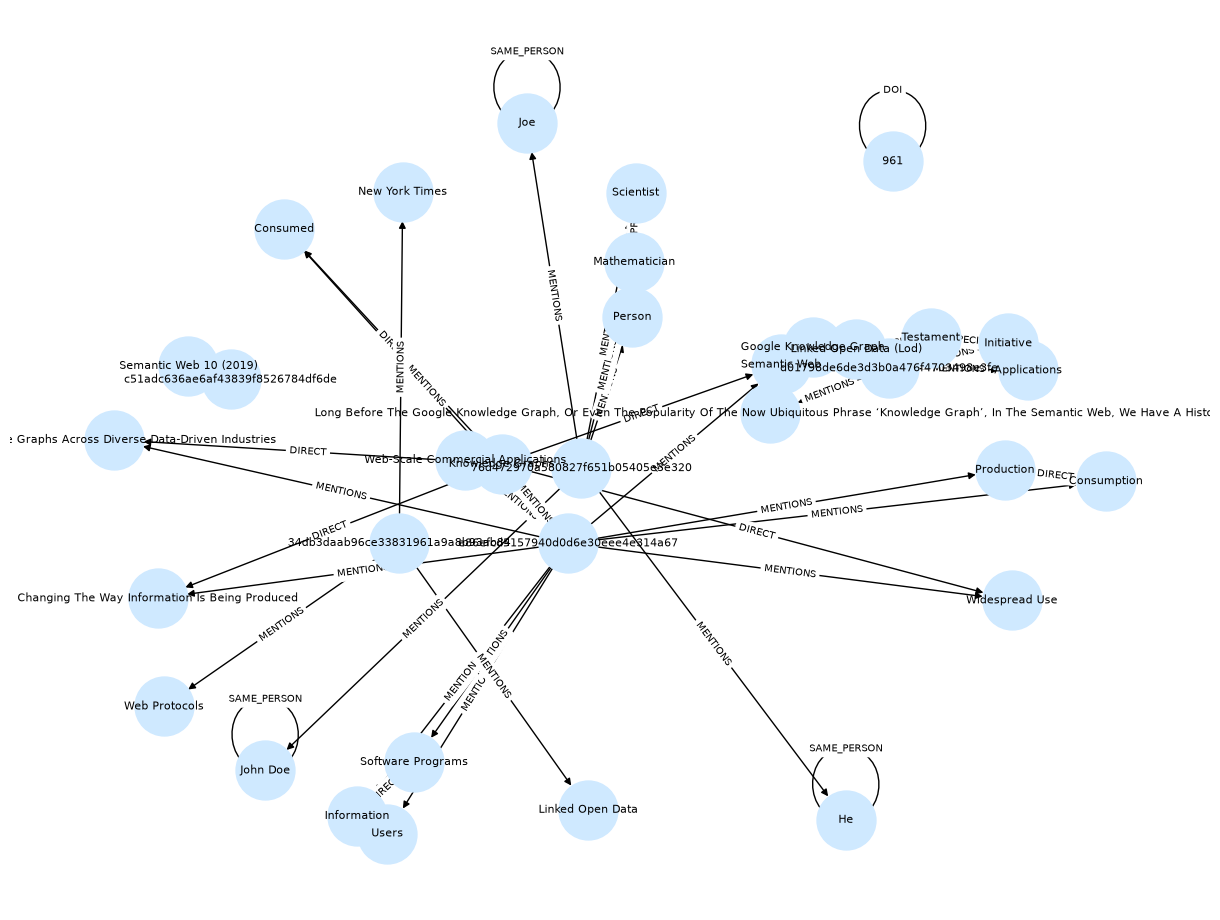

In [64]:
# Build the graph
G = get_graph_from_neo4j(driver)

# 3. Draw it
import matplotlib.pyplot as plt

# Calculate where to place each node so they don't overlap
pos = nx.spring_layout(G, seed=3)

plt.figure(figsize=(12, 9))  # size of the picture

# Draw the nodes and arrows
nx.draw(
    G, pos,
    with_labels=True,          # show node names
    node_color="#cfe9ff",      # light blue nodes
    node_size=1800,
    font_size=8,
    arrows=True                # show arrow direction
)

# Draw the relationship names on top of each arrow (e.g. "ENROLLED_IN")
edge_labels = nx.get_edge_attributes(G, "label")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7)

plt.show()  # actually display the picture

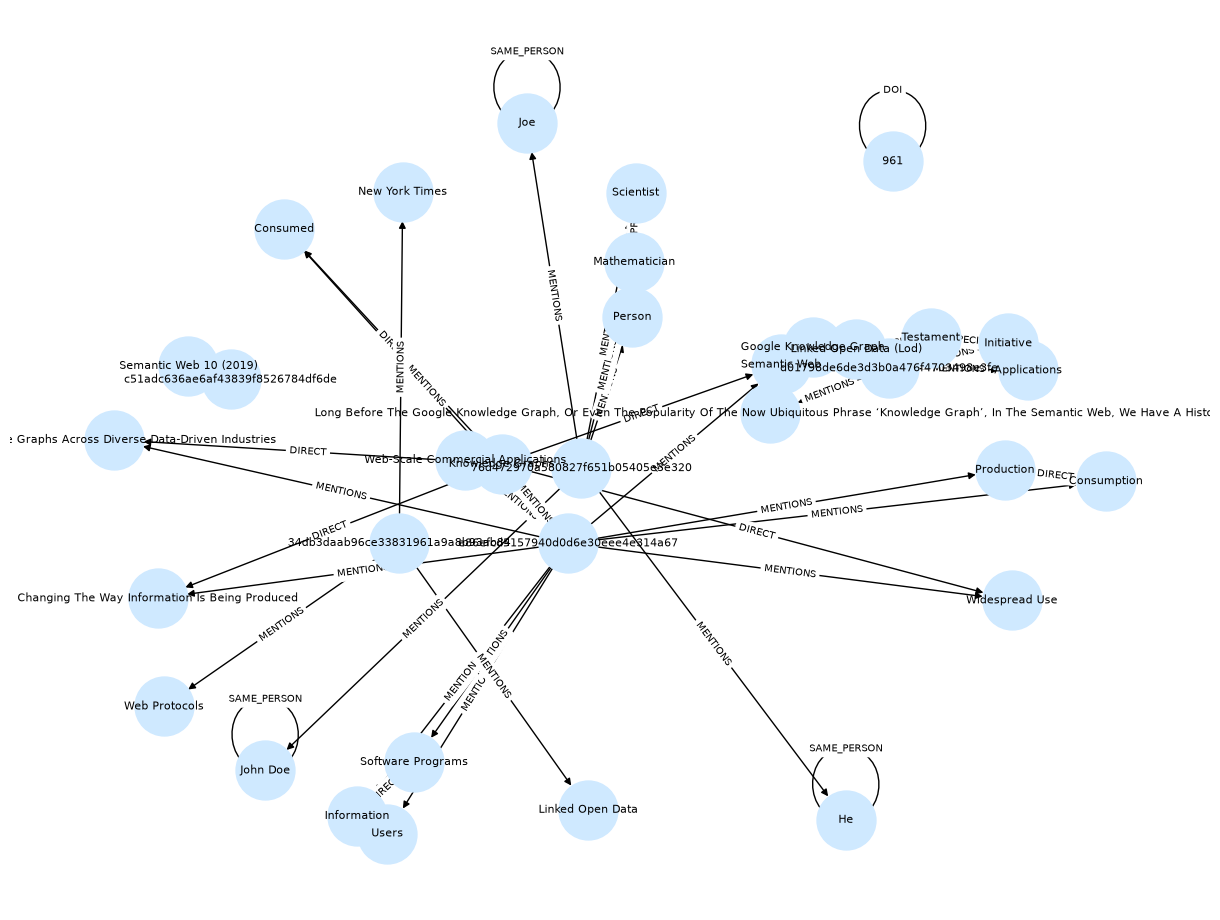

In [65]:
# Build the graph
G = get_graph_from_neo4j(driver)

# 3. Draw it
import matplotlib.pyplot as plt

# Calculate where to place each node so they don't overlap
pos = nx.spring_layout(G, seed=3)

plt.figure(figsize=(12, 9))  # size of the picture

# Draw the nodes and arrows
nx.draw(
    G, pos,
    with_labels=True,          # show node names
    node_color="#cfe9ff",      # light blue nodes
    node_size=1800,
    font_size=8,
    arrows=True                # show arrow direction
)

# Draw the relationship names on top of each arrow (e.g. "ENROLLED_IN")
edge_labels = nx.get_edge_attributes(G, "label")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7)

plt.show()  # actually display the picture

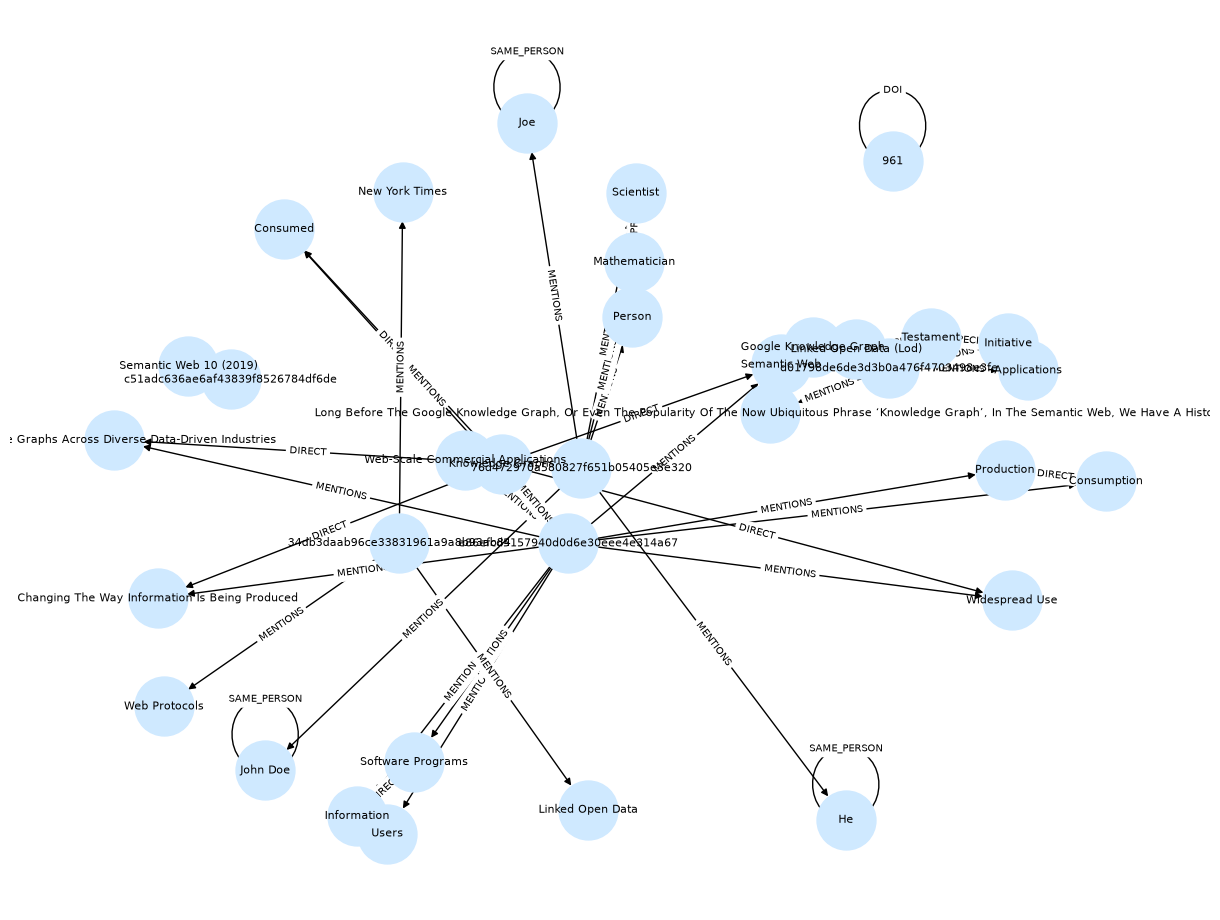

In [66]:
# Build the graph
G = get_graph_from_neo4j(driver)

# 3. Draw it
import matplotlib.pyplot as plt

# Calculate where to place each node so they don't overlap
pos = nx.spring_layout(G, seed=3)

plt.figure(figsize=(12, 9))  # size of the picture

# Draw the nodes and arrows
nx.draw(
    G, pos,
    with_labels=True,          # show node names
    node_color="#cfe9ff",      # light blue nodes
    node_size=1800,
    font_size=8,
    arrows=True                # show arrow direction
)

# Draw the relationship names on top of each arrow (e.g. "ENROLLED_IN")
edge_labels = nx.get_edge_attributes(G, "label")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7)

plt.show()  # actually display the picture

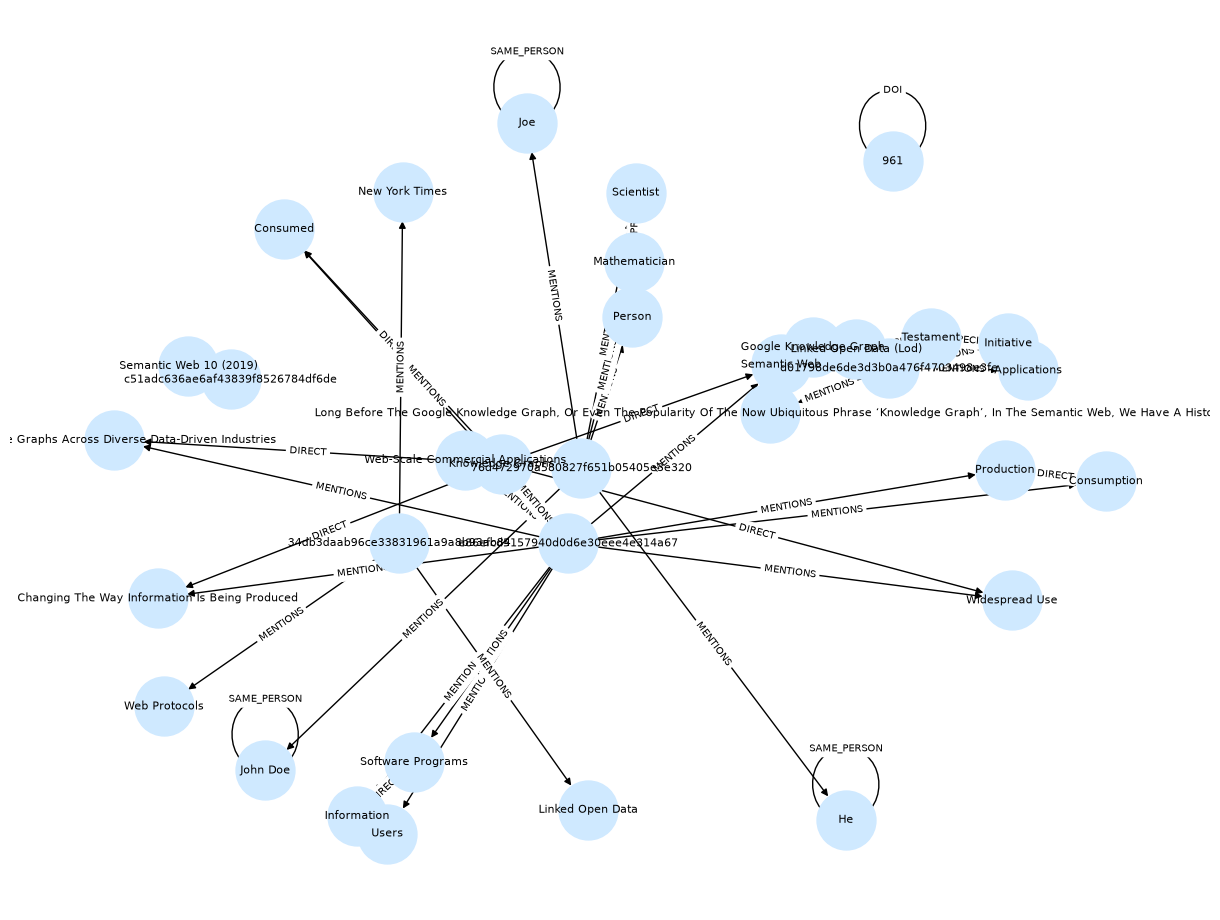

In [67]:
# Build the graph
G = get_graph_from_neo4j(driver)

# 3. Draw it
import matplotlib.pyplot as plt

# Calculate where to place each node so they don't overlap
pos = nx.spring_layout(G, seed=3)

plt.figure(figsize=(12, 9))  # size of the picture

# Draw the nodes and arrows
nx.draw(
    G, pos,
    with_labels=True,          # show node names
    node_color="#cfe9ff",      # light blue nodes
    node_size=1800,
    font_size=8,
    arrows=True                # show arrow direction
)

# Draw the relationship names on top of each arrow (e.g. "ENROLLED_IN")
edge_labels = nx.get_edge_attributes(G, "label")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7)

plt.show()  # actually display the picture

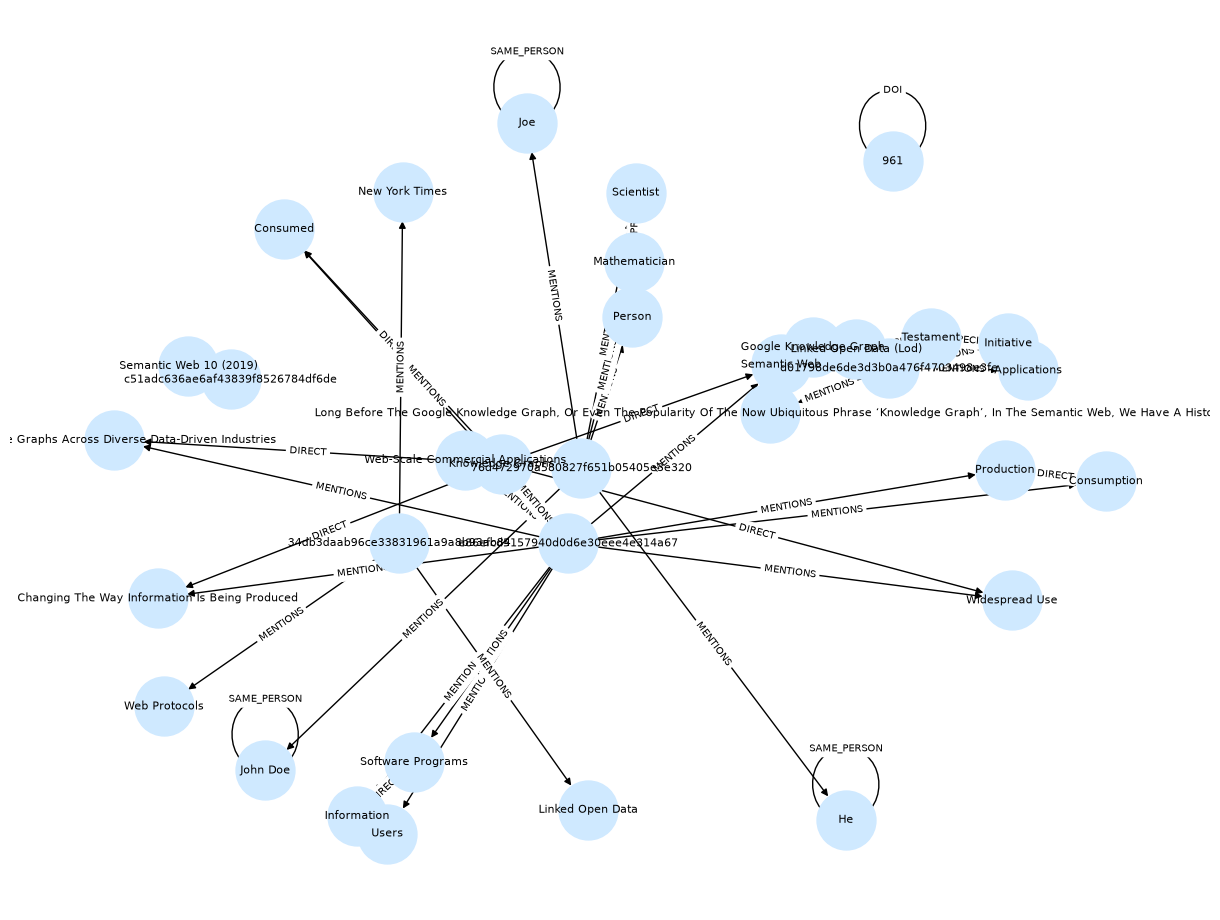

In [68]:
# Build the graph
G = get_graph_from_neo4j(driver)

# 3. Draw it
import matplotlib.pyplot as plt

# Calculate where to place each node so they don't overlap
pos = nx.spring_layout(G, seed=3)

plt.figure(figsize=(12, 9))  # size of the picture

# Draw the nodes and arrows
nx.draw(
    G, pos,
    with_labels=True,          # show node names
    node_color="#cfe9ff",      # light blue nodes
    node_size=1800,
    font_size=8,
    arrows=True                # show arrow direction
)

# Draw the relationship names on top of each arrow (e.g. "ENROLLED_IN")
edge_labels = nx.get_edge_attributes(G, "label")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7)

plt.show()  # actually display the picture

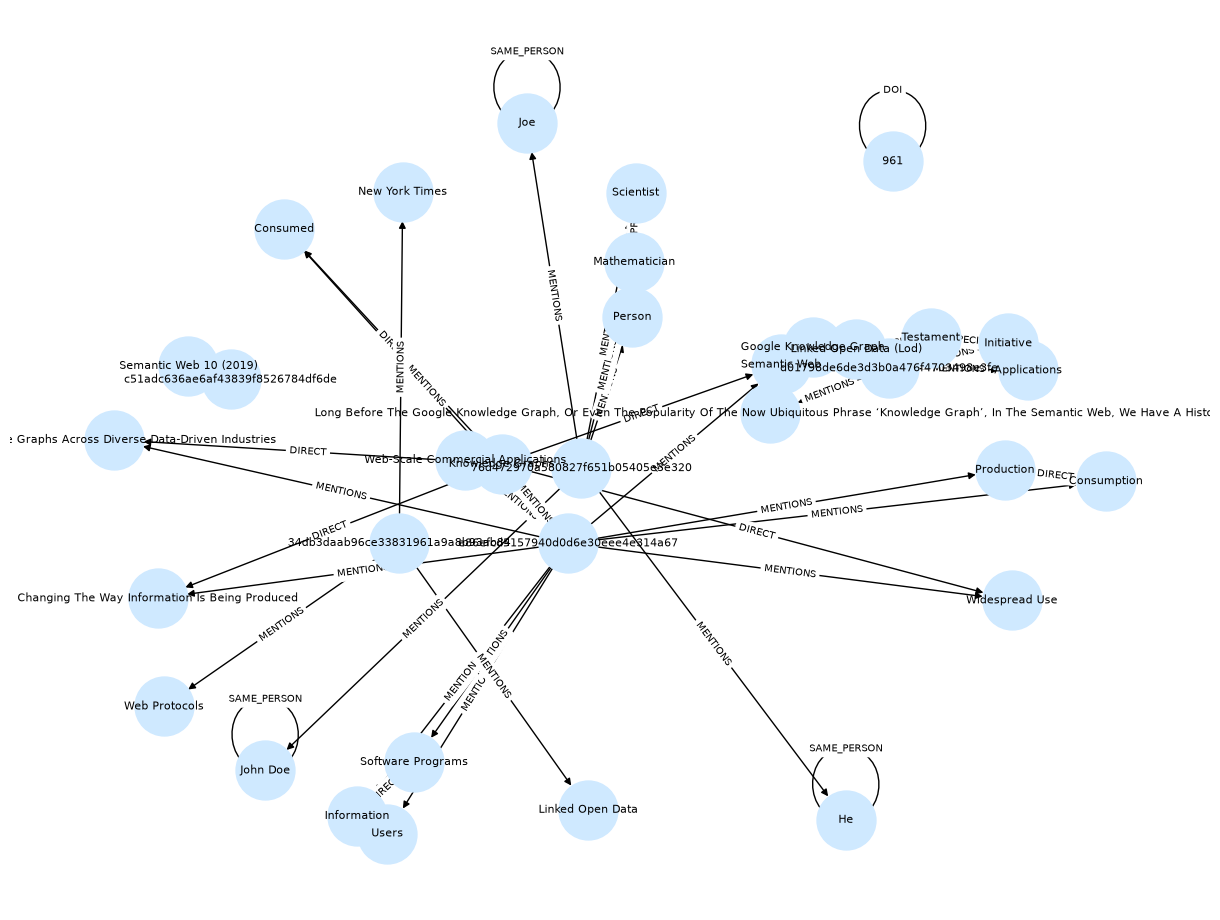

In [69]:
# Build the graph
G = get_graph_from_neo4j(driver)

# 3. Draw it
import matplotlib.pyplot as plt

# Calculate where to place each node so they don't overlap
pos = nx.spring_layout(G, seed=3)

plt.figure(figsize=(12, 9))  # size of the picture

# Draw the nodes and arrows
nx.draw(
    G, pos,
    with_labels=True,          # show node names
    node_color="#cfe9ff",      # light blue nodes
    node_size=1800,
    font_size=8,
    arrows=True                # show arrow direction
)

# Draw the relationship names on top of each arrow (e.g. "ENROLLED_IN")
edge_labels = nx.get_edge_attributes(G, "label")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7)

plt.show()  # actually display the picture

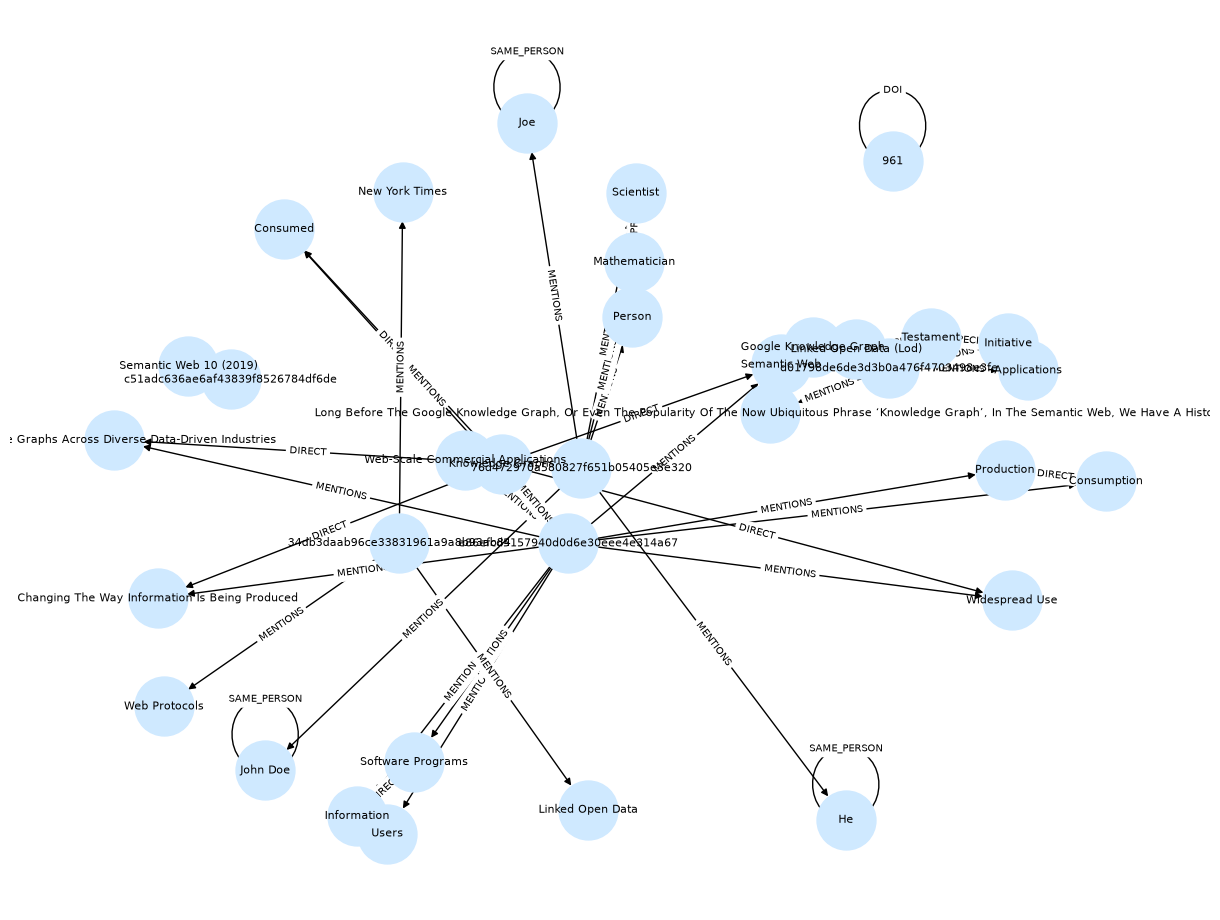

In [70]:
# Build the graph
G = get_graph_from_neo4j(driver)

# 3. Draw it
import matplotlib.pyplot as plt

# Calculate where to place each node so they don't overlap
pos = nx.spring_layout(G, seed=3)

plt.figure(figsize=(12, 9))  # size of the picture

# Draw the nodes and arrows
nx.draw(
    G, pos,
    with_labels=True,          # show node names
    node_color="#cfe9ff",      # light blue nodes
    node_size=1800,
    font_size=8,
    arrows=True                # show arrow direction
)

# Draw the relationship names on top of each arrow (e.g. "ENROLLED_IN")
edge_labels = nx.get_edge_attributes(G, "label")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7)

plt.show()  # actually display the picture